<!-- d2l:prose id=few-step-md-1 fw=all -->

# Few-Step Generation

A diffusion model draws a sample by calling its network again and again.
The samplers of that section brought the thousand calls
of the ancestral chain down to about fifty, and the latent models of
that section made each call cheaper, but fifty is still
fifty, and the generator of a GAN (that section) needed one. Why not
take a single long step? It fails, and not for lack of a good network: even
with the exact velocity field, one Euler step of the probability-flow ODE
sends every start to the mean of the data
(that section). For a mixture of three blobs that
point lies between the blobs, where no data are.

A velocity tells the sampler which way to move; one step needs to know
where it will end up. So we let the network learn the solution of the ODE
instead of its right-hand side, a map from a point at one time to where its
trajectory is at an earlier time. @Song.Dhariwal.Chen.ea.2023
learned the jump to the data by distilling a trained diffusion model, the
*teacher*, into a new network, the *student*, and called the student a
*consistency model*. @Geng.Deng.Bai.ea.2025 learned jumps over any
interval from data alone and called the method *MeanFlow*. Training remains
a regression with one network, and the same noise always gives the same
sample, so a student can be compared with its teacher image by image.
that section trained one-step generators against a critic
instead; we return to that route at the end. First we see what one and a
few Euler steps get wrong, then derive one loss for both methods and train
students on the running example and on Fashion-MNIST.

In [1]:
import math
import numpy as np
import torch
from torch import nn
from torch.nn import functional as F
from d2l import torch as d2l

In [2]:
import copy

In [3]:
torch.set_float32_matmul_precision('high')  # tf32 matmuls on tensor cores

<!-- d2l:prose id=few-step-md-2 fw=all -->

## Long Euler Steps

On an exact field a long Euler step makes one error: it follows the
tangent while the trajectory bends. At $t = 1$ this error is as large as it
can be: from every start the velocity points at the data mean, and a step
of length one lands there (that section). Later steps start from points that have begun to commit to a mode
and aim better, but each still cuts across the curve.

### Euler Steps on the Exact Field

that section showed one, ten and a hundred steps;
what do two and four leave? `mix.velocity` evaluates the exact field of the
mixture, `d2l.make_pred` turns it into the predictor that `d2l.ode_sample`
integrates, and we run Euler's method with 1, 2, 4 and 10 steps from the
same 20,000 Gaussian starts. The rows for two and four steps are the
baseline that the students of this section must beat.

 1 Euler steps: weights [1.0, 0.0, 0.0], stray 100.0%
 2 Euler steps: weights [0.644, 0.217, 0.14], stray 25.1%
 4 Euler steps: weights [0.54, 0.277, 0.183], stray 6.5%
10 Euler steps: weights [0.512, 0.291, 0.197], stray 2.2%


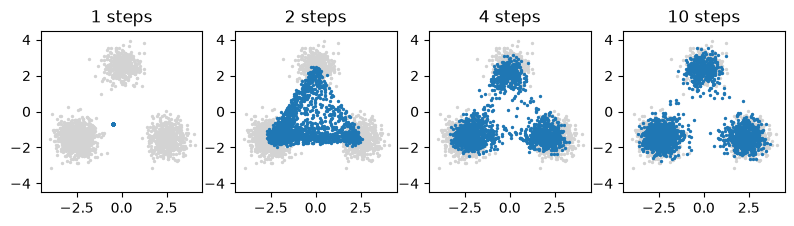

In [4]:
device = d2l.try_gpu()
mix = d2l.GaussianMixture.three_modes(device)
lin = d2l.GaussianPath.linear()
pred_exact = d2l.make_pred(mix.velocity, lin, 'velocity')
torch.manual_seed(0)
z = torch.randn(20_000, 2, device=device)
euler = {n: d2l.ode_sample(pred_exact, z, lin.sigma_bars(n))
         for n in (1, 2, 4, 10)}
for n, x in euler.items():
    s = mix.summary(x)
    print(f'{n:2d} Euler steps: weights {s["weights"]}, '
          f'stray {s["stray"]:.1%}')
d2l.scatter_panels([x[:2000] for x in euler.values()],
                   [f'{n} steps' for n in euler], data=mix.sample(2000),
                   size=2.4);

<!-- d2l:prose id=few-step-md-3 fw=all -->

One step puts every sample on the mean $(-0.5, -0.7)$, which `summary`
counts as stray and assigns to the nearest mode, the heaviest: hence the
weights 1/0/0. Two steps reach the modes but leave about a quarter of the
samples between them, with weights of about 0.64/0.22/0.14 instead of
0.5/0.3/0.2. The first half-step still aims at the mean, which lies
nearest to the heaviest mode, and that mode gains. Four steps still leave
about 6.5% of the samples stray, and ten about 2%, against about 1% for
the data themselves. With an exact field, the excess is the error of the
step.

### Reflow

Why do the trajectories bend at all? Each training example joins a data
point to an independently drawn noise vector by a straight segment, but
the segments of different examples cross. Where they cross, the field
averages their directions, and the trajectories, which cannot cross, bend
around each other (that section). The curvature comes
from the pairing of noise with data, not from the loss.

*Reflow* [@Liu.Gong.Liu.2022] changes the pairing. It pairs each noise
vector with the sample that a trained model reaches from it and trains the
network again on these pairs. Each new segment is the chord of one
trajectory of the old model, and since those trajectories never cross,
their chords rarely do. that section proves that reflow
with the exact field keeps the data distribution and never increases the
transport cost, and on two-moons data one Euler step of the reflowed model
scores as well as many steps of the original.

A trained field weakens the guarantee. The new pairs end at the model's
samples, not at the data, so the reflowed model inherits the original's
errors: on two moons it reproduces the original's samples, their blur
included (that section), and an image model passes on
every defect of its samples in the same way. Each round also costs a
training run, and the best one-step results of @Liu.Gong.Liu.2022
still came from distilling the reflowed model. The rest of this section
changes what the network outputs instead of how the data are paired.

## Flow Maps

A velocity model says which way a trajectory points; a flow map says where
it arrives.

### The Integral of the Velocity

Run the probability-flow ODE $d\mathbf{x}_\tau / d\tau =
\mathbf{u}_\tau(\mathbf{x}_\tau)$ from a point $\mathbf{x}$ at time $t$
back to an earlier time $s \leq t$. The point where it arrives is the
*flow map* $\Phi_{t \to s}(\mathbf{x})$. For a field that is Lipschitz in
$\mathbf{x}$ the exact flow map is a bijection
(that section), and the sampler we want is
$\Phi_{1 \to 0}$.

Integrating the ODE along the trajectory $\mathbf{x}_\tau$ through
$\mathbf{x}_t$ writes the flow map as a displacement,

$$\Phi_{t \to s}(\mathbf{x}_t) = \mathbf{x}_t - \int_s^t \mathbf{u}_\tau(\mathbf{x}_\tau)\, d\tau = \mathbf{x}_t - (t - s)\, \bar{\mathbf{u}}(\mathbf{x}_t, s, t),$$

where $\bar{\mathbf{u}}(\mathbf{x}_t, s, t)$ is the *average velocity* along
the trajectory between the two times. Euler's method replaces it by the
velocity at the start, $\mathbf{u}_t(\mathbf{x}_t)$, with an error that
grows with the step (that section). Over an interval
of length zero the two agree, $\bar{\mathbf{u}}(\mathbf{x}, t, t) =
\mathbf{u}_t(\mathbf{x})$, so a network for $\bar{\mathbf{u}}$ is a velocity
model with one more input, the end time.

The smallest case shows what the average velocity knows that the velocity
does not. Let the data be one-dimensional and Gaussian with mean $m$ and
standard deviation $\varsigma$. Then $x_t$ is Gaussian with mean $(1 - t)\,
m$ and standard deviation $k_t = \sqrt{(1 - t)^2 \varsigma^2 + t^2}$. In
one dimension trajectories cannot pass each other, so the flow keeps each
point's quantile, and for a Gaussian the quantile is fixed by the
standardized position $(x - (1 - t) m) / k_t$. The flow map is therefore
affine:

$$\Phi_{t \to s}(x) = (1 - s)\, m + \frac{k_s}{k_t} \big(x - (1 - t)\, m\big).$$

With $m = 2$ and $\varsigma = 0.5$ the full jump $\Phi_{1 \to 0}(x) = 2 +
0.5\, x$ sends standard Gaussian noise to the data $\mathcal{N}(2, 0.5^2)$,
with average velocity $\bar{u}(x, 0, 1) = 0.5\, x - 2$. The velocity at the
start is $u_1(x) = x - 2$, and its Euler step returns 2 for every $x$. The
average velocity removes only half of the noise, because half of the
noise's spread must survive as the spread of the data.

How can a network learn $\Phi$ when nobody can tell it the values? Through
an identity that only the true flow map satisfies, turned into a loss.
There is one identity for each way of moving the two times along a
trajectory (the figure). Let $\mathbf{x}_\tau$ be the
trajectory through $\mathbf{x}$ at time $t$, and $s \leq r \leq t$.

The *compositional* identity says that two jumps make one,
$\Phi_{r \to s}(\Phi_{t \to r}(\mathbf{x})) = \Phi_{t \to s}(\mathbf{x})$.
A loss built on it needs no derivative, only the model at an intermediate
time, and its target is as accurate as the shorter jumps it is built from.
Progressive distillation [@Salimans.Ho.2022] and shortcut models
[@Frans.Hafner.Levine.ea.2025] use it.

The *Lagrangian* identity fixes the start and moves the end. The mapped
point then moves with the field, like a particle,
$\partial_s \Phi_{t \to s}(\mathbf{x}) = \mathbf{u}_s(\Phi_{t \to s}(\mathbf{x}))$.
A loss built on it needs the velocity at the point where the jump lands. A
training example gives its conditional velocity only at its own
$\mathbf{x}_t$, so a teacher must supply the velocity there, or the flow
map itself (Exercise 3).

The *Eulerian* identity fixes the end and slides the start along the
trajectory: every point of one trajectory maps to the same place,

$$\frac{d}{dt} \Phi_{t \to s}(\mathbf{x}_t) = \partial_t \Phi_{t \to s}(\mathbf{x}_t) + \nabla_{\mathbf{x}} \Phi_{t \to s}(\mathbf{x}_t)\, \mathbf{u}_t(\mathbf{x}_t) = \mathbf{0}.$$

A loss built on it needs one Jacobian-vector product and the velocity at
the start, where the training example has one, and its target involves a
single pair of times, with no intermediate time and no step size.

In the Gaussian example all three can be checked by hand: the ratios
$k_s / k_t$ compose; the point $\Phi_{t \to s}(x)$, followed as $s$ varies,
keeps its standardized position and so moves as a point of the flow does;
and the standardized position is constant along a trajectory.

![The flow map. Left: trajectories of the probability-flow ODE for a one-dimensional mixture of two Gaussians, from the noise at $t = 1$ (top) to the data at $t = 0$ (bottom); the chord from $(\mathbf{x}_t, t)$ to $(\mathbf{x}_s, s)$ is one jump of the flow map. Right, on one trajectory: two jumps through $r$ make one (compositional); the start fixed at $t$ and the end moving (Lagrangian); the end fixed at $s$ and the start moving (Eulerian).](../img/mdl-diffusion-flow-map.svg)

Together with the condition at $s = t$, where the map is the identity and
its slope in $s$ is the velocity, each identity determines the flow map.
They differ only in what a loss must compute. Composition is the simplest;
the Eulerian identity is the only one that needs neither an intermediate
time nor a velocity where the jump lands; it needs one Jacobian-vector
product instead. Consistency models and MeanFlow both use the
Eulerian identity; @Boffi.Albergo.VandenEijnden.2025 sort the
few-step methods by the identity they enforce.

### Consistency Models

The first flow-map method kept only the jump to the data. A *consistency
model* [@Song.Dhariwal.Chen.ea.2023] is a network $f(\mathbf{x}, t)$
trained to output $\Phi_{t \to 0}(\mathbf{x})$ at every time. Its training
condition is that the output does not change as the input moves along a
trajectory, $\frac{d}{dt} f(\mathbf{x}_t, t) = \mathbf{0}$ with
$f(\mathbf{x}, 0) = \mathbf{x}$, the Eulerian identity
the equation at $s = 0$.

In *consistency distillation*, Song et al. let the teacher take one ODE
step between neighboring times of a grid, and require the student's outputs at the two points to agree. The output at
the earlier point serves as the target; it is held fixed and computed with
a moving average of the student's weights. As the grid is refined the
difference, divided by the step, becomes the derivative above, which
@Lu.Song.2025 use directly. *Consistency training* needs no
teacher: it replaces the teacher's velocity by the velocity
$\boldsymbol\epsilon - \mathbf{x}_0$ of each training example's straight
segment, the conditional velocity of flow matching.

One evaluation of a consistency model gives a sample. A second cannot jump
from $t = 1$ to $t = 0.5$, because the model knows only where trajectories
end. It *re-noises* instead: the sample is moved back to $t = 0.5$ with
fresh noise, $\mathbf{x}_{0.5} = 0.5\, \mathbf{x}_0 + 0.5\,
\boldsymbol\epsilon'$, and mapped to the data again, from a point where
trajectories bend less. A flow map with both times needs no re-noising:
two evaluations are two jumps along one trajectory, and the sample still
depends on the starting noise alone.

### Average Velocity and the MeanFlow Identity

Writing the flow map through the average velocity
the equation turns the Eulerian identity into a
regression target. Multiply the average velocity by the length of its
interval, which gives the integral of the velocity, and differentiate in
$t$ along the trajectory with $s$ held fixed:

$$\frac{d}{dt} \Big[(t - s)\, \bar{\mathbf{u}}(\mathbf{x}_t, s, t)\Big] = \frac{d}{dt} \int_s^t \mathbf{u}_\tau(\mathbf{x}_\tau)\, d\tau = \mathbf{u}_t(\mathbf{x}_t).$$

The product rule on the left gives the *MeanFlow identity* of
@Geng.Deng.Bai.ea.2025,

$$\bar{\mathbf{u}}(\mathbf{x}_t, s, t) = \mathbf{u}_t(\mathbf{x}_t) - (t - s)\, \frac{d}{dt} \bar{\mathbf{u}}(\mathbf{x}_t, s, t).$$

The average velocity is the velocity at the start, corrected by how fast
the average changes as the start slides along the trajectory. Substituting
the equation into the equation shows
that the two identities are the same. The total derivative is
$\partial_t \bar{\mathbf{u}} + (\nabla_{\mathbf{x}} \bar{\mathbf{u}})\,
\mathbf{u}_t$, the Jacobian-vector product of the network $(\mathbf{x}, t)
\mapsto \bar{\mathbf{u}}(\mathbf{x}, s, t)$ with the tangent
$(\mathbf{u}_t, 1)$, which forward-mode differentiation computes together
with the output at about the cost of a backward pass. A training step
thus costs about one backward pass more than a step of a velocity model,
plus one evaluation of the teacher when there is a teacher.

The identity becomes a loss by regressing the network onto its right-hand
side, computed from the network itself and held fixed. The marginal
velocity $\mathbf{u}_t$ is not available, but two substitutes are. A
teacher provides its estimate $\hat{\mathbf{u}}$ of
$\mathbf{u}_t(\mathbf{x}_t)$. Without one, the conditional velocity
$\boldsymbol\epsilon - \mathbf{x}_0$ of the training example serves, for
the reason that made flow matching work. The target is affine in the
velocity, directly and through the tangent of the Jacobian-vector product.
Averaged over the examples that could have produced $\mathbf{x}_t$, it is
therefore the target with $\mathbf{u}_t(\mathbf{x}_t)$ in place of the
conditional velocity, and squared error is minimized by that average.
Writing $\mathbf{u}_{\textrm{ref}}$ for the velocity we use, the *reference
velocity*, the loss at a training point is

$$
\begin{aligned}
\Big\| \bar{\mathbf{u}}_{\boldsymbol\theta}(\mathbf{x}_t, s, t) - \mathrm{sg}\Big[\mathbf{u}_{\textrm{ref}} - (t - s)\, \frac{d}{dt} \bar{\mathbf{u}}_{\boldsymbol\theta}(\mathbf{x}_t, s, t)\Big] \Big\|^2,
\end{aligned}
$$

where $\mathrm{sg}$, the *stop-gradient*, marks a quantity treated as a
constant when the loss is differentiated. It is required by the averaging
argument just made, which holds only if the network enters the loss
through the prediction alone. Differentiated through the target, the
network could lower the loss by reshaping the Jacobian inside the target,
which changes how much the target varies between examples, instead of by
satisfying the identity (Exercise 4). Of
all the steps of the derivation this is the one a reimplementation most
easily gets wrong, since the code with and without it differs by a single
stop-gradient call.

<!-- d2l:prose id=few-step-md-4 fw=pytorch -->

The call is `.detach()`.

<!-- d2l:prose id=few-step-md-5 fw=all -->

The loss leaves two choices: where $\mathbf{u}_{\textrm{ref}}$ comes from,
and whether the end time $s$ is free or fixed at zero. The main methods
fall into the four combinations, although some enforce the identity by
other means than this loss, and each adds details of its own that
that section describes.

| velocity $\mathbf{u}_{\textrm{ref}}$ | one time, $s = 0$ | two times, $s \leq t$ |
|---|---|---|
| a teacher's $\hat{\mathbf{u}}$ | consistency distillation | flow-map distillation [@Kim.Lai.Liao.ea.2024] |
| the example's $\boldsymbol\epsilon - \mathbf{x}_0$ | consistency training | MeanFlow |

At $s = 0$, the equation reads $f(\mathbf{x}, t) =
\mathbf{x} - t\, \bar{\mathbf{u}}(\mathbf{x}, 0, t)$, so the top-left cell
is consistency distillation in the continuous-time form of
@Lu.Song.2025 . `flow_map_error` implements
the equation per example on the linear path for all
four: the network `u` computes $\bar{\mathbf{u}}$, `teacher=None` selects
the conditional velocity, and the caller chooses the times and averages.

In [5]:
def flow_map_error(u, teacher, x0, eps, s, t):
    """Per-example squared error of the average velocity u(x_t, s, t) against
    the stop-gradient target v - (t - s) du/dt; v from teacher, or eps - x0."""
    x_t = d2l.GaussianPath.linear().sample(x0, t, eps)
    if teacher is None:
        v = eps - x0
    else:
        with torch.no_grad():
            v = teacher(x_t, t)
    u_t, du_dt = torch.func.jvp(lambda x, r: u(x, s, r), (x_t, t),
                                (v, torch.ones_like(t)))
    gap = (t - s).reshape(-1, *[1] * (x0.dim() - 1))
    target = (v - gap * du_dt).detach()
    return ((u_t - target) ** 2).flatten(1).sum(1)

<!-- d2l:prose id=few-step-md-6 fw=all -->

The derivative in $t$ passes through the network's time features, which
is why the flow maps use slower ones than the rest of the chapter. A
feature $\sin(\omega t)$ has the derivative $\omega \cos(\omega t)$, so
each feature enters the target multiplied by its frequency. The other
networks see $t$ at frequencies up to 64 (that section);
the flow maps pass `time_freqs=slow`, frequencies from $10^{-4}$ to one,
which the code below defines as `slow`. Large frequencies put large factors
into the derivative (code that embeds $1000\, t$ multiplies it by up to a
thousand), a source of instability that @Lu.Song.2025 report for
consistency models.

A flow map takes $\mathbf{x}_t$ to $\mathbf{x}_s$ in one jump,
$\mathbf{x}_s = \mathbf{x}_t - (t - s)\, \bar{\mathbf{u}}(\mathbf{x}_t, s,
t)$, so a few-step sampler cuts $[0, 1]$ into equal intervals and jumps
across each.

In [6]:
@torch.inference_mode()
def flow_map_sample(u, x, steps, t_start=1.0):
    """Jump from x at t_start (1 is noise) to data at t = 0 in equal steps."""
    ts = torch.linspace(t_start, 0, steps + 1, device=x.device)
    for t, s in zip(ts[:-1], ts[1:]):
        x = x - (t - s) * u(x, s.expand(len(x)), t.expand(len(x)))
    return x

<!-- d2l:prose id=few-step-md-7 fw=all -->

With the velocity $\mathbf{u}_t$ in place of $\bar{\mathbf{u}}$, the same
function is Euler's method, so one sampler serves the teacher and the
student. The jumps go one way only: every loss of this section draws
$s \leq t$, so inverting a sample, as that section
inverted the ODE, would need the map trained in the other direction too.

For the image experiment at the end of the next section, the student
starts as a copy of the teacher's U-Net. The gap $t - s$ enters through
its own time embedding and a linear map initialized at zero, added to the
U-Net's embedding, so that at the start $\bar{\mathbf{u}}(\mathbf{x}, s, t)
= \hat{\mathbf{u}}(\mathbf{x}, t)$, the teacher's velocity.

In [7]:
class UNetFlowMap(nn.Module):
    """u(x, s, t): a velocity U-Net, plus a zero-initialized input for the
    gap t - s. The caller passes a copy of the teacher's U-Net."""
    def __init__(self, unet):
        super().__init__()
        # the teacher is an EMA copy with gradients off; the student trains
        self.unet = unet.requires_grad_(True)
        self.gap = nn.Linear(unet.emb_dim, unet.emb_dim)
        nn.init.zeros_(self.gap.weight), nn.init.zeros_(self.gap.bias)

    def forward(self, x, s, t):
        gap = self.gap(d2l.time_embedding(t - s, self.unet.emb_dim,
                                          self.unet.time_freqs))
        return self.unet(x, t, cond=gap)

<!-- d2l:prose id=few-step-md-8 fw=all -->

## Training Flow Maps

### The Three-Mode Mixture

Does the loss work, and does it matter where the reference velocity comes
from? The mixture can answer both, because its exact field tells us what a
perfect sampler prints. The teacher is a velocity model trained as in
that section: a `TimeMLP`, which passes the point
and sine features of $t$ through layers of width 256, here trained for
20,000 steps.

In [8]:
torch.manual_seed(1)
_, teacher, _ = d2l.train_regression(
    d2l.TimeMLP(256, 3).to(device), d2l.regression_loss(lin, 'velocity'),
    lambda: mix.sample(512), 20_000, cosine=True)

<!-- d2l:prose id=few-step-md-9 fw=all -->

Three students fill three cells of the table.
All are `TimeMLP`s that see the start $t$ and the interval $t - s$,
trained like the teacher, six times each (seeds 2 to 7), so that we can
tell a property of a method from an accident of one run. The consistency
student draws $t$ uniformly, fixes $s = 0$ and uses the teacher's
velocity. The flow-map distillation student draws two uniform times, takes
the smaller as $s$, and uses the teacher's velocity too; the MeanFlow
student draws its times the same way and uses no teacher. The fourth cell,
consistency training, needs no student of its own: its two choices, one
time and the example's velocity, are each tested by another student.

What losses should we expect? A distilled student's target is a function
of the point and the times, so its loss can approach zero. MeanFlow's
target contains each example's own velocity twice, once as
$\mathbf{u}_{\textrm{ref}}$ and once as the direction of the tangent, and
its loss cannot fall below the variation of that target between examples
at the same point and times.

In [9]:
class MLPFlowMap(d2l.TimeMLP):
    """u(x, s, t): a TimeMLP on the start t and the interval t - s."""
    def forward(self, x, s, t):
        return super().forward(x, t, t - s)

slow = (1e-4, 1.0)  # time features of a flow map, whose loss has a d/dt

def consistency_loss(u, x0):  # s = 0, the teacher's velocity
    t = torch.rand(len(x0), device=device)
    return d2l.flow_map_error(u, teacher, x0, torch.randn_like(x0),
                              torch.zeros_like(t), t).mean()

def distillation_loss(u, x0):  # s < t, the teacher's velocity
    a, b = torch.rand(2, len(x0), device=device)
    s, t = torch.minimum(a, b), torch.maximum(a, b)
    return d2l.flow_map_error(u, teacher, x0, torch.randn_like(x0), s,
                              t).mean()

def meanflow_loss(u, x0):  # s < t, no teacher
    a, b = torch.rand(2, len(x0), device=device)
    s, t = torch.minimum(a, b), torch.maximum(a, b)
    return d2l.flow_map_error(u, None, x0, torch.randn_like(x0), s, t).mean()

students = {}
for name, loss in (('consistency', consistency_loss),
                   ('distillation', distillation_loss),
                   ('MeanFlow', meanflow_loss)):
    final = []
    for seed in range(2, 8):
        torch.manual_seed(seed)
        _, students[name, seed], losses = d2l.train_regression(
            MLPFlowMap(256, 3, num_times=2, time_freqs=slow).to(device),
            loss, lambda: mix.sample(512), 20_000, cosine=True)
        final.append(float(losses[-1000:].mean()))
    print(f'{name:>12}, seeds 2 to 7: mean loss of the last 1,000 updates '
          f'{min(final):.3f} to {max(final):.3f}')

 consistency, seeds 2 to 7: mean loss of the last 1,000 updates 0.073 to 0.083


distillation, seeds 2 to 7: mean loss of the last 1,000 updates 0.030 to 0.037


    MeanFlow, seeds 2 to 7: mean loss of the last 1,000 updates 76.136 to 81.287


<!-- d2l:prose id=few-step-md-10 fw=all -->

The distilled students end near zero, about 0.03 for the two-time student
and 0.06 to 0.08 for the consistency student. MeanFlow ends at 76 to 85
over its six runs, about a thousand times the consistency student's loss.
Most of that may be the floor, the disagreement between examples that no
network can remove; the cell does not measure the floor, so the number
says little about the student. MeanFlow runs are judged by their samples, not by their
losses.

All models now start from the 20,000 points of the Euler experiment: the
teacher with fifty Euler steps, the consistency student with one jump or
two with re-noising at $t = 0.5$, the two-time students with one, two or
four jumps. A fresh draw from the mixture shows what a perfect sampler
would print. A row of the table gives the largest error in the three
weights for each run, six for a student in the order of its seeds and one
for the data and the teacher. It then gives, as a range over the runs, the
strays, the samples farther than three standard deviations from every mode
center, and the spread, the mean squared distance of the samples that do
not stray to the center of their mode (that section).

                          largest weight error, each run       stray      spread
                    data  0.005                                0.9%       0.474
       teacher, 50 steps  0.003                                1.6%       0.461
          consistency, 1  0.003 0.003 0.003 0.003 0.003 0.003  2.0%-2.1%  0.457-0.461
consistency, 2 re-noised  0.003 0.002 0.004 0.004 0.003 0.003  1.2%-1.5%  0.472-0.482
         distillation, 1  0.003 0.003 0.003 0.003 0.003 0.003  1.9%-2.1%  0.446-0.453
         distillation, 2  0.004 0.004 0.004 0.003 0.004 0.004  1.0%-1.1%  0.464-0.473
         distillation, 4  0.004 0.003 0.003 0.003 0.004 0.003  0.8%-1.0%  0.457-0.465
             MeanFlow, 1  0.007 0.002 0.004 0.002 0.006 0.002  4.0%-4.4%  0.314-0.339
             MeanFlow, 2  0.003 0.003 0.007 0.009 0.008 0.007  1.3%-1.7%  0.364-0.379
             MeanFlow, 4  0.005 0.005 0.007 0.010 0.023 0.007  0.7%-0.9%  0.360-0.376


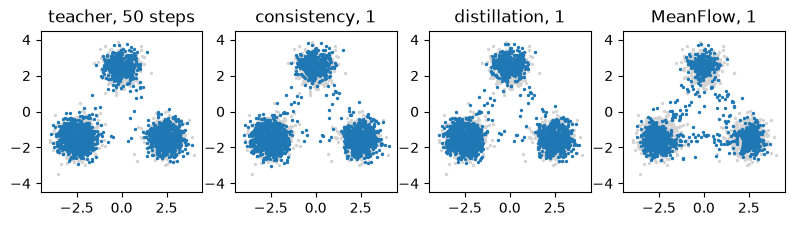

In [10]:
def renoised_sample(u, z):
    """Two evaluations of a one-time map: jump, re-noise to t = 0.5, jump."""
    x = d2l.flow_map_sample(u, z, 1)
    half = torch.full((len(z),), 0.5, device=device)
    return d2l.flow_map_sample(u, lin.sample(x, half, torch.randn_like(x)), 1,
                               t_start=0.5)

def span(values, fmt):
    """'lo-hi' over the runs, or the one value if they print alike."""
    lo, hi = format(min(values), fmt), format(max(values), fmt)
    return lo if lo == hi else f'{lo}-{hi}'

def report(name, xs):
    """Each run's largest weight error; the range of strays and spreads."""
    stats, w_true = [mix.summary(x) for x in xs], mix.weights.tolist()
    err = ' '.join(
        f'{max(abs(w - w0) for w, w0 in zip(s["weights"], w_true)):.3f}'
        for s in stats)
    print(f'{name:>24}  {err:35}  {span([s["stray"] for s in stats], ".1%"):9}'
          f'  {span([s["spread"] for s in stats], ".3f")}')

torch.manual_seed(4)
samples = {'data': [mix.sample(len(z))],
           'teacher, 50 steps': [d2l.flow_map_sample(
               lambda x, s, t: teacher(x, t), z, 50)]}
for (name, seed), u in students.items():
    if name == 'consistency':  # a one-time map re-noises for a second step
        new = {'1': d2l.flow_map_sample(u, z, 1),
               '2 re-noised': renoised_sample(u, z)}
    else:
        new = {str(k): d2l.flow_map_sample(u, z, k) for k in (1, 2, 4)}
    for k, x in new.items():
        samples.setdefault(f'{name}, {k}', []).append(x)
print(f'{"":24}  {"largest weight error, each run":35}  {"stray":9}  spread')
for name, xs in samples.items():
    report(name, xs)
names = ['teacher, 50 steps', 'consistency, 1', 'distillation, 1',
         'MeanFlow, 1']
d2l.scatter_panels([samples[k][0][:2000] for k in names], names,
                   data=mix.sample(2000), size=2.4);

<!-- d2l:prose id=few-step-md-11 fw=all -->

After one evaluation every run of every student puts its samples on the
three modes with weights within 0.007 of 0.5/0.3/0.2. A fresh draw of
20,000 points misses by 0.004 to 0.005, so one jump gets the weights right
to within about the noise of sampling, and the distilled two-time student
keeps them that close at two and four jumps. The fresh draw strays about 1%
of the time, the tail of each Gaussian beyond three standard deviations,
and the teacher with fifty steps about 1.5%. Both distilled students stray
about 2% after one evaluation and keep the data's spread, 0.45 to 0.46
against 0.47. A second evaluation brings their strays to the teacher's
level or below, whether it re-noises (1.2% to 1.5%) or jumps again (1.0% to
1.1%). On the mixture re-noising costs nothing these numbers can see; what
the second jump keeps is the pairing of each sample with its noise.
MeanFlow strays about 4% after one jump, and its panel shows a second
defect: the modes are too tight, with a spread of 0.31 to 0.34 after one
jump and 0.35 to 0.40 after two and four. That is also why its four jumps
stray no more often than the data themselves.

The six runs also show where a single run would mislead. The distilled
student's weights stay within 0.006 at two and four jumps in every run.
MeanFlow's do not: after four jumps one or two runs in six end 0.013 to
0.023 off, two to six times the miss of a fresh draw, while the others stay
within 0.010. MeanFlow's weights after several jumps thus depend on the
training run, and one run is no guide to them; the distilled student's do
not.

<!-- d2l:prose id=few-step-md-12 fw=pytorch -->

In this tab the drifting run is the one with seed 6, the fifth column of
the table: 0.023 off after four jumps.

<!-- d2l:prose id=few-step-md-13 fw=all -->

The comparison locates the defect. The two-time students share the
network, the time pairs and the updates and differ only in the velocity
inside the target. Their spreads never overlap: every distilled run lies
more than 0.1 above every MeanFlow run after one jump and at least 0.06
above after two and four, while the six runs of one student span at most
0.013 (distilled) and about 0.04 (MeanFlow). In this experiment, then, the
contraction comes from training on the examples' velocities. Why a noisy
target ends in a map that is too tight rather than a noisy one, the runs do
not say. A student that has learned only part of the correction term of
the equation is partly an Euler step, and Euler strides
contract the modes in just this way (that section), but
that is a plausible reading, not a result. On the mixture a teacher is
worth having: training from data alone saves the teacher's run but leaves
the student a far noisier target to average.

### Fashion-MNIST

The image teacher is an unconditional velocity U-Net, `UNet(ch=64)` with
about 1.2 million parameters, trained for 10,000 updates with the slow
time features, since the student starts as a copy of it.
`train_regression` returns a moving average of the weights along with the
trained network, and that averaged network is the teacher.

In [11]:
X, y, X_test, y_test = d2l.load_fashion_mnist_pm1()

def batch_fn():
    return X[torch.randint(0, len(X), (128,), device=X.device)]

torch.manual_seed(0)
_, teacher, _ = d2l.train_regression(  # the student copies these time features
    d2l.UNet(ch=64, time_freqs=slow).to(X.device),
    d2l.regression_loss(lin, 'velocity'), batch_fn, 10_000)

<!-- d2l:prose id=few-step-md-14 fw=all -->

We score 1,000 samples by the Fréchet distance (FD) of
that section against 1,000 test images: the distance
between Gaussians fitted to the features that a Fashion-MNIST classifier
extracts from the two sets. It is read against the floor of two disjoint
sets of 1,000 test images.

In [12]:
cnn = d2l.fashion_feature_cnn(X, y)
features = lambda imgs: d2l.fd_features(cnn, imgs)
f_test = features(X_test[:1000])
floor = d2l.fid_score(features(X_test[1000:2000]), f_test)
print(f'floor, 1,000 real images against 1,000 others: FD {floor:.2f}')

floor, 1,000 real images against 1,000 others: FD 0.82


<!-- d2l:prose id=few-step-md-15 fw=all -->

The student is `UNetFlowMap`, defined above, on a copy of the teacher,
trained with the teacher's velocity and both times free. Half of the pairs
have $s = t$, where the target is the teacher's velocity itself: the
student starts as the teacher, and these pairs are meant to keep it from
forgetting the velocity while it learns to jump. The other half draw
$s < t$ as on the mixture. Starting from trained weights, the student
learns at a rate of $2 \cdot 10^{-4}$ for 5,000 updates of 128 images,
half the teacher's 10,000. We train two students from the same teacher,
with seeds 2 and 3, to see how much of the result belongs to the run.

In [13]:
def student_loss(u, x0):
    a, b = torch.rand(2, len(x0), device=x0.device)
    s, t = torch.minimum(a, b), torch.maximum(a, b)
    # half the pairs have s = t: the teacher's velocity as target
    s = torch.where(torch.rand(len(x0), device=x0.device) < 0.5, t, s)
    return d2l.flow_map_error(u, teacher, x0, torch.randn_like(x0), s,
                              t).mean()

image_students = {}
for seed in (2, 3):
    torch.manual_seed(seed)
    _, image_students[seed], _ = d2l.train_regression(
        d2l.UNetFlowMap(copy.deepcopy(teacher)).to(X.device), student_loss,
        batch_fn, 5_000, lr=2e-4, ema_half_life=500,
        compiled=False)  # jvp through GroupNorm won't compile

<!-- d2l:prose id=few-step-md-16 fw=all -->

From the same 1,000 noise images, the teacher takes 1 to 50 Euler steps
and each student 1, 2 or 4 jumps, and we plot FD against the number of
network evaluations. The teacher's single step should land on the mean
image, the pixel version of the mixture's failure, so its FD there should
dwarf every other point.

FD at evaluations       1       2       4      10      20      50
teacher            166.05   83.00   26.97    6.60    3.55    2.50
student 2           11.74    4.32    3.45
student 3           11.52    4.61    3.77


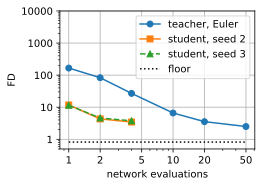

In [14]:
torch.manual_seed(3)
noise = torch.randn(1000, 1, 28, 28, device=X.device)
velocity = lambda x, s, t: teacher(x, t)
ns_teacher, ns_student = (1, 2, 4, 10, 20, 50), (1, 2, 4)
images = {('teacher', n): d2l.flow_map_sample(velocity, noise, n)
          for n in ns_teacher}
images |= {(f'student {seed}', n): d2l.flow_map_sample(u, noise, n)
           for seed, u in image_students.items() for n in ns_student}
fd = {key: d2l.fid_score(features(x), f_test) for key, x in images.items()}
print('FD at evaluations' + ''.join(f'{n:8d}' for n in ns_teacher))
for name in ['teacher', *(f'student {seed}' for seed in image_students)]:
    print(f'{name:17}' + ''.join(f'{fd[name, n]:8.2f}' for n in ns_teacher
                                 if (name, n) in fd))
d2l.plot([ns_teacher, ns_student, ns_student, [1, 50]],
         [[fd['teacher', n] for n in ns_teacher],
          *[[fd[f'student {seed}', n] for n in ns_student]
            for seed in image_students], [floor, floor]],
         'network evaluations', 'FD', ylim=(0.5, 1e4), xscale='log',
         yscale='log', fmts=('o-', 's-', '^--', 'k:'),
         legend=['teacher, Euler', 'student, seed 2', 'student, seed 3',
                 'floor'], legend_loc='upper right')

<!-- d2l:prose id=few-step-md-17 fw=all -->

The teacher's FD falls from about 145 to 170 at one Euler step and about
80 at two, to about 7 at ten and about 2.6 at fifty, against a floor of
about 0.8. The students lie far below this curve at small budgets: one jump
scores 11 to 12, between four and five times the teacher's fifty-step FD,
two jumps nearly twice it, and four 1.4 to 1.5 times, close to what the
teacher reaches in twenty steps. Read across the plot, two jumps of a
student land between the teacher's ten and twenty Euler steps, and one jump
between its four and ten. The two students agree to within a tenth of
their FD at every budget, so these readings hold for either of them.

A distilled student can at best reproduce its teacher's ODE, so its target
is the FD of the teacher's exact ODE, which fifty Euler steps approach from
above, not the floor. How much of the remaining gap is a matter of
training, our runs do not tell. Each student saw 640,000 images; published
students are trained on far more and come much closer to their teachers in
one step [@Song.Dhariwal.Chen.ea.2023; @Lu.Song.2025].

The rows below are drawn from the same eight noise images: the teacher
with fifty and with two Euler steps, and the student with seed 2 with one
and with two jumps.

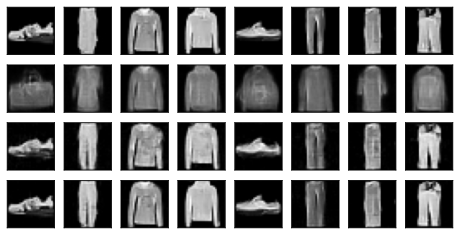

In [15]:
rows = [('teacher', 50), ('teacher', 2), ('student 2', 1), ('student 2', 2)]
d2l.show_gray(torch.cat([images[r][:8].clamp(-1, 1) for r in rows]), 4, 8);

<!-- d2l:prose id=few-step-md-18 fw=all -->

The rows match column by column. Two Euler steps of the teacher draw gray
averages of garments, the mixture's failure in pixels, and in some columns
not even the kind of garment that fifty steps draw. The student, from the
same noise, draws the teacher's garment in almost every column after a
single evaluation. What one jump loses is detail: prints and stripes
smudge, an outline turns ragged here and there, and a few blotches appear.
A second jump brings most columns close to the teacher's fifty steps.

## Distribution Matching

A flow map is bounded by the trajectories it learns from: a distilled
student by its teacher's ODE, and a student trained from data alone by how
well it learns the exact field, which on the mixture fell short in the
spread.

The other route trains a one-step generator
$g_{\boldsymbol\theta}(\mathbf{z})$ to match a distribution instead of a
trajectory. Fitted by squared error to a teacher's samples, such a
generator draws averages: a network that cannot reproduce the teacher's
long computation in one pass sees several noise vectors as alike, and
squared error rewards the mean of their images (that section).
That section also gave two remedies: a critic against real images
[@Sauer.Lorenz.Blattmann.ea.2023], and distribution matching
distillation [@Yin.Gharbi.Zhang.ea.2024], which needs no critic. The
latter noises the generator's samples, $\mathbf{x}_t = (1 - t)\,
g_{\boldsymbol\theta}(\mathbf{z}) + t\, \boldsymbol\epsilon$, and lowers
the Kullback-Leibler divergence of their law $q_{\boldsymbol\theta, t}$
from the noised data $p_t$. Its gradient is

$$
\begin{aligned}
&\nabla_{\boldsymbol\theta} D_{\textrm{KL}}(q_{\boldsymbol\theta, t} \,\|\, p_t) \\
&\qquad = \mathbb{E}\Big[\big(\nabla \log q_{\boldsymbol\theta, t}(\mathbf{x}_t) - \nabla \log p_t(\mathbf{x}_t)\big)^\top \frac{\partial \mathbf{x}_t}{\partial \boldsymbol\theta}\Big].
\end{aligned}
$$

The gradient is the student's score minus the teacher's, so a descent step
moves each noised sample toward where the data have more mass than the
student puts there. The teacher supplies $\nabla \log p_t$, since on the
linear path the score is an affine function of the velocity
the equation, and a second diffusion model,
trained alongside on the student's own samples, supplies
$\nabla \log q_{\boldsymbol\theta, t}$
(the figure). Such a student is bounded by
its teacher's distribution rather than its trajectories; only a loss with
real images in it, a critic as in adversarial distillation or added to
distribution matching [@Yin.Gharbi.Park.ea.2024], lets a student
surpass its teacher (that section). Neither variant
is trained along trajectories of the ODE, so the generator's sample for a
given noise vector need not be the teacher's, and inversion and editing
through the ODE no longer apply.

![Distribution matching distillation. The student maps noise $\mathbf{z}$ to a sample in one step, and the sample is noised to a time $t$. The frozen teacher supplies the score $\nabla \log p_t$ of the noised data at $\mathbf{x}_t$. A second diffusion model, trained alongside on the student's samples (orange), supplies the score $\nabla \log q_{\boldsymbol\theta, t}$ of the noised samples. The difference of the two scores is the gradient that reaches the student (red).](../img/mdl-diffusion-dmd.svg)

What to pick follows from the budget. At fifty evaluations a teacher with
a good solver needs no second training run. When latency matters, distill
a two-time flow map from the teacher: on Fashion-MNIST two of its jumps
landed between the teacher's ten and twenty Euler steps. Without a teacher,
MeanFlow trains a flow map from data alone, but on the mixture, with the
plain squared error we used, it drew modes that are too tight; the
published recipe reweights the loss
(Exercise 4). Distribution matching, with or without a critic,
also reaches one step, but gives up the map from noise to sample that
inversion and editing need.

Both routes start from the same object: a continuous path along which a
velocity or a score is defined. Neither exists when $\mathbf{x}$ is a
sequence of tokens, the subject of that section.

## Summary

- A single Euler step of the probability-flow ODE from $t = 1$ to $t = 0$ collapses every starting point onto the data mean $\mathbb{E}[\mathbf{x}_0]$ because it follows the initial tangent of a curved trajectory.
- A flow map $\Phi_{t \to s}(\mathbf{x}_t) = \mathbf{x}_t - (t - s)\, \bar{\mathbf{u}}(\mathbf{x}_t, s, t)$ predicts the integrated displacement along the ODE trajectory via the average velocity $\bar{\mathbf{u}}$. Differentiating with respect to $t$ yields the Eulerian / MeanFlow identity $\bar{\mathbf{u}} = \mathbf{u}_t - (t - s)\, \frac{d}{dt}\bar{\mathbf{u}}$, which can be trained with one forward-mode Jacobian-vector product and a stop-gradient target.
- Pairing the reference velocity $\mathbf{u}_{\textrm{ref}}$ (a pretrained teacher $\hat{\mathbf{u}}$ versus the conditional velocity $\boldsymbol\epsilon - \mathbf{x}_0$) with the time domain ($s = 0$ versus $s \le t$) unifies consistency distillation, consistency training, flow-map distillation, and MeanFlow.
- On the three-mode mixture and Fashion-MNIST, flow-map distillation from a teacher accurately preserves within-mode spread and matches 10–20 teacher Euler steps in 2–4 student jumps, whereas teacher-free MeanFlow, trained here with plain squared error on noisy per-example velocities, contracts the modes of the mixture.

## Exercises

1. **One and two Euler steps.**
    1. A single step of the deterministic sampler from pure noise to $t = 0$
       returns $\mathbb{E}[\mathbf{x}_0]$ from every start, whatever the
       path (that section). Does the same hold for
       one Euler step in $t$, $\mathbf{x} - \mathbf{u}_1(\mathbf{x})$, on the
       cosine path $\alpha_t = \cos\frac{\pi t}{2}$,
       $\sigma_t = \sin\frac{\pi t}{2}$? What does that step return, and
       why does an Euler step in $t$ depend on the path when a step in
       $\bar\sigma$ does not?
    1. Let the data be the two points $\pm a$ in one dimension, with equal
       probability, on the linear path. Show that
       $\mathbb{E}[x_0 \mid x_t = x] = a \tanh\big(a (1 - t) x / t^2\big)$
       and that two Euler steps of length $\tfrac12$ map a start $x$ to
       $a \tanh(a x)$. that section has the exact flow
       of this example.
    1. For $a = 2$, what fraction of the two-step samples lies within $0.1$
       of a data point? Where does the exact flow map $\Phi_{1 \to 0}$ send
       $x$?
1. [code] **Reflow on the mixture.** ● Reflow [@Liu.Gong.Liu.2022]
   retrains a velocity model on pairs of a noise vector and the sample that
   the current model produces from it.
    1. Draw 20,000 noise vectors, integrate the teacher of this section with
       fifty Euler steps, and train a new `TimeMLP` on the pairs with the
       velocity loss and the teacher's settings.
    1. Report the weights and strays of the new model at 1, 2, 4 and 10
       Euler steps, and the mean distance of its fifty-step trajectories
       from their chords, next to the same quantities for the teacher.
    1. Which of the teacher's errors does reflow remove, which does it
       inherit, and which does it add? What would a second round do to each?
1. **The Lagrangian loss.** ● @Boffi.Albergo.VandenEijnden.2025
   train flow maps with the Lagrangian identity.
    1. Substitute the equation into $\partial_s
       \Phi_{t \to s}(\mathbf{x}) = \mathbf{u}_s(\Phi_{t \to s}(\mathbf{x}))$
       and derive an identity for $\bar{\mathbf{u}}$ that involves the
       velocity at the output of the jump.
    1. Why can the conditional velocity $\boldsymbol\epsilon - \mathbf{x}_0$
       not serve in this identity, so that a velocity model is needed? Show
       that the flow map's own velocity $\bar{\mathbf{u}}(\cdot, s, s)$ can
       serve, so that one network trains itself.
    1. [code] Train such a student on the mixture and compare it with the
       MeanFlow student in strays and in training cost per step.
1. [code] **The stop-gradient and the weighting.** Two details of
   the equation decide what its minimizer is.
    1. Copy `flow_map_error` into a cell and remove the stop-gradient on
       the target. Train the MeanFlow student on the mixture with this loss
       and report its one-step weights, strays and spread. Write out the
       gradient of the loss with the target differentiated, and identify
       the term that the stop-gradient removes. What can the network change
       to lower this loss without satisfying the equation?
    1. Song et al. compute the target with a moving average of the
       student's weights instead. Implement this with `d2l.EMA` and compare.
    1. MeanFlow's ImageNet recipe [@Geng.Deng.Bai.ea.2025] divides
       each example's squared error $e$ by $e + c$, held fixed, with a small
       $c$, so that the gradient is that of $\log(e + c)$. Squared error is
       minimized by the conditional mean of the target; near which value
       does the weighted loss put its minimizer? Without a teacher the
       targets at a noisy point of the mixture spread over the three modes:
       predict the mode weights of one-jump samples, then train the MeanFlow
       student with this weight and $c = 10^{-3}$ and check.
    1. On a $28 \times 28$ image, $e$ sums 784 squared errors. Argue that
       it then varies far less between examples at the same $(s, t)$ than
       in two dimensions, so that the weight acts mostly as a weighting
       across times. What does the experiment on the mixture tell you about
       the recipe on images, and what does it not?
1. [code] **A guided student.** ● Classifier-free guidance, as in
   that section, evaluates the network twice
   per step. @Meng.Rombach.Gao.ea.2023 distill the guided velocity
   into one network, which halves the cost of every step before the number
   of steps is reduced. Train the class-conditional U-Net of
   that section with `time_freqs=slow`, as this section's
   image teacher was trained, and distill it into a two-time student whose reference
   velocity $\mathbf{u}_{\textrm{ref}}$ is the guided velocity
   $\tilde{\mathbf{u}}$, `d2l.cfg(teacher, c, 2.0)`, for random labels $c$,
   with the label as an input of the student.
    1. Compare the FD and the agreement of the predicted class with the
       requested one for the teacher with fifty guided Euler steps and the
       student with one, two and four jumps.
    1. How many network evaluations does each sample cost in each case?
    1. Meng et al. also give the student the guidance strength as an input.
       How would you draw the strengths during training, and what does the
       student then offer that a student distilled at $\gamma = 2$ does not?
1. **Matching noised distributions.** ● Distribution matching distillation
   [@Yin.Gharbi.Zhang.ea.2024] trains a one-step generator
   $\mathbf{x} = g_{\boldsymbol\theta}(\mathbf{z})$ along the gradient
   the equation, where $q_{\boldsymbol\theta, t}$ is
   the law of the noised samples $\mathbf{x}_t$.
    1. Derive the equation. Why does the term from
       the dependence of $q_{\boldsymbol\theta, t}$ itself on
       $\boldsymbol\theta$ vanish?
    1. In one dimension, let the generator be $m + b z$ with $b > 0$ and
       the data $\mathcal{N}(\mu, v)$. Write
       $D_{\textrm{KL}}(q_t \,\|\, p_t)$ on the linear path in closed form,
       and show that $m = \mu$, $b^2 = v$ is its only minimizer at every
       $t < 1$.
    1. Let the data be $\tfrac12 \mathcal{N}(-2, 0.25) + \tfrac12 \mathcal{N}(2, 0.25)$.
       Evaluate $D_{\textrm{KL}}(q_t \,\|\, p_t)$ by quadrature on a grid of
       $(m, b)$ at $t \in \{0.1, 0.3, 0.5, 0.9\}$, and locate the minimizer
       at each $t$. Why is the minimum near $\log 2$ at small $t$? Relate the
       result to mode dropping in GANs (that section)
       and to the merging of modes under noise (Exercise
       4 of that section).
       What does a weighting of the levels toward large $t$ gain for a
       Gaussian generator, and what can no weighting gain for it?

[Discussions](https://d2l.discourse.group/t/36893)